In [ ]:
import os

from utils import get_hdf5_files, get_filename, get_continuous_behaviors, get_discrete_states, get_eigenworms, get_kymograph, get_neuronal_traces

import math
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA

# read data

In [ ]:
hdf5files = get_hdf5_files()
filenames = [get_filename(file) for file in hdf5files]

outpath = './out/neuron_correlates'
os.makedirs(outpath, exist_ok=True)

# neuron correlates

In [ ]:
traces = [get_neuronal_traces(file) for file in hdf5files]

In [ ]:
n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(50, 50))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, trace in enumerate(traces):
	correlation = trace.corr()
	heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
	heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
	heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)

	image = np.frombuffer(heatmap.figure.canvas.tostring_argb(), dtype='uint8')
	image = image.reshape(heatmap.figure.canvas.get_width_height()[::-1] + (4,))
	image = image[:, :, [1, 2, 3]]

	axes[i // dim, i % dim].imshow(image)
	axes[i // dim, i % dim].axis('off')
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}', fontsize=25)

	plt.savefig(f'{outpath}/{filenames[i][:-14]}.png', dpi=300)
	plt.close(heatmap.figure)

plt.tight_layout(pad=0.2, w_pad=0.2, h_pad=0.2)
plt.show()

# neuron residual correlates

In [ ]:
n = 1

traces_residual = list()
for i in range(len(filenames)):
	trace = traces[i]
	pca = PCA(n_components=n)
	trace_reduced = pca.fit_transform(trace)
	trace_reconstructed = pca.inverse_transform(trace_reduced)
	trace_residuals = trace - trace_reconstructed
	traces_residual.append(trace_residuals)

os.makedirs(f'{outpath}/residuals/pc{n}', exist_ok=True)

n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(50, 50))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, trace in enumerate(traces_residual):
	correlation = trace.corr()
	heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
	heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
	heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)

	image = np.frombuffer(heatmap.figure.canvas.tostring_argb(), dtype='uint8')
	image = image.reshape(heatmap.figure.canvas.get_width_height()[::-1] + (4,))
	image = image[:, :, [1, 2, 3]]

	axes[i // dim, i % dim].imshow(image)
	axes[i // dim, i % dim].axis('off')
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}', fontsize=25)

	plt.savefig(f'{outpath}/residuals/pc{n}/{filenames[i][:-14]}.png', dpi=300)
	plt.close(heatmap.figure)

plt.tight_layout(pad=0.2, w_pad=0.2, h_pad=0.2)
plt.show()


In [ ]:
n = 2

traces_residual = list()
for i in range(len(filenames)):
	trace = traces[i]
	pca = PCA(n_components=n)
	trace_reduced = pca.fit_transform(trace)
	trace_reconstructed = pca.inverse_transform(trace_reduced)
	trace_residuals = trace - trace_reconstructed
	traces_residual.append(trace_residuals)

os.makedirs(f'{outpath}/residuals/pc{n}', exist_ok=True)

n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(50, 50))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, trace in enumerate(traces_residual):
	correlation = trace.corr()
	heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
	heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
	heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)

	image = np.frombuffer(heatmap.figure.canvas.tostring_argb(), dtype='uint8')
	image = image.reshape(heatmap.figure.canvas.get_width_height()[::-1] + (4,))
	image = image[:, :, [1, 2, 3]]

	axes[i // dim, i % dim].imshow(image)
	axes[i // dim, i % dim].axis('off')
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}', fontsize=25)

	plt.savefig(f'{outpath}/residuals/pc{n}/{filenames[i][:-14]}.png', dpi=300)
	plt.close(heatmap.figure)

plt.tight_layout(pad=0.2, w_pad=0.2, h_pad=0.2)
plt.show()


In [ ]:
n = 3

traces_residual = list()
for i in range(len(filenames)):
	trace = traces[i]
	pca = PCA(n_components=n)
	trace_reduced = pca.fit_transform(trace)
	trace_reconstructed = pca.inverse_transform(trace_reduced)
	trace_residuals = trace - trace_reconstructed
	traces_residual.append(trace_residuals)

os.makedirs(f'{outpath}/residuals/pc{n}', exist_ok=True)

n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(50, 50))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, trace in enumerate(traces_residual):
	correlation = trace.corr()
	heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
	heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
	heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)

	image = np.frombuffer(heatmap.figure.canvas.tostring_argb(), dtype='uint8')
	image = image.reshape(heatmap.figure.canvas.get_width_height()[::-1] + (4,))
	image = image[:, :, [1, 2, 3]]

	axes[i // dim, i % dim].imshow(image)
	axes[i // dim, i % dim].axis('off')
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}', fontsize=25)

	plt.savefig(f'{outpath}/residuals/pc{n}/{filenames[i][:-14]}.png', dpi=300)
	plt.close(heatmap.figure)

plt.tight_layout(pad=0.2, w_pad=0.2, h_pad=0.2)
plt.show()


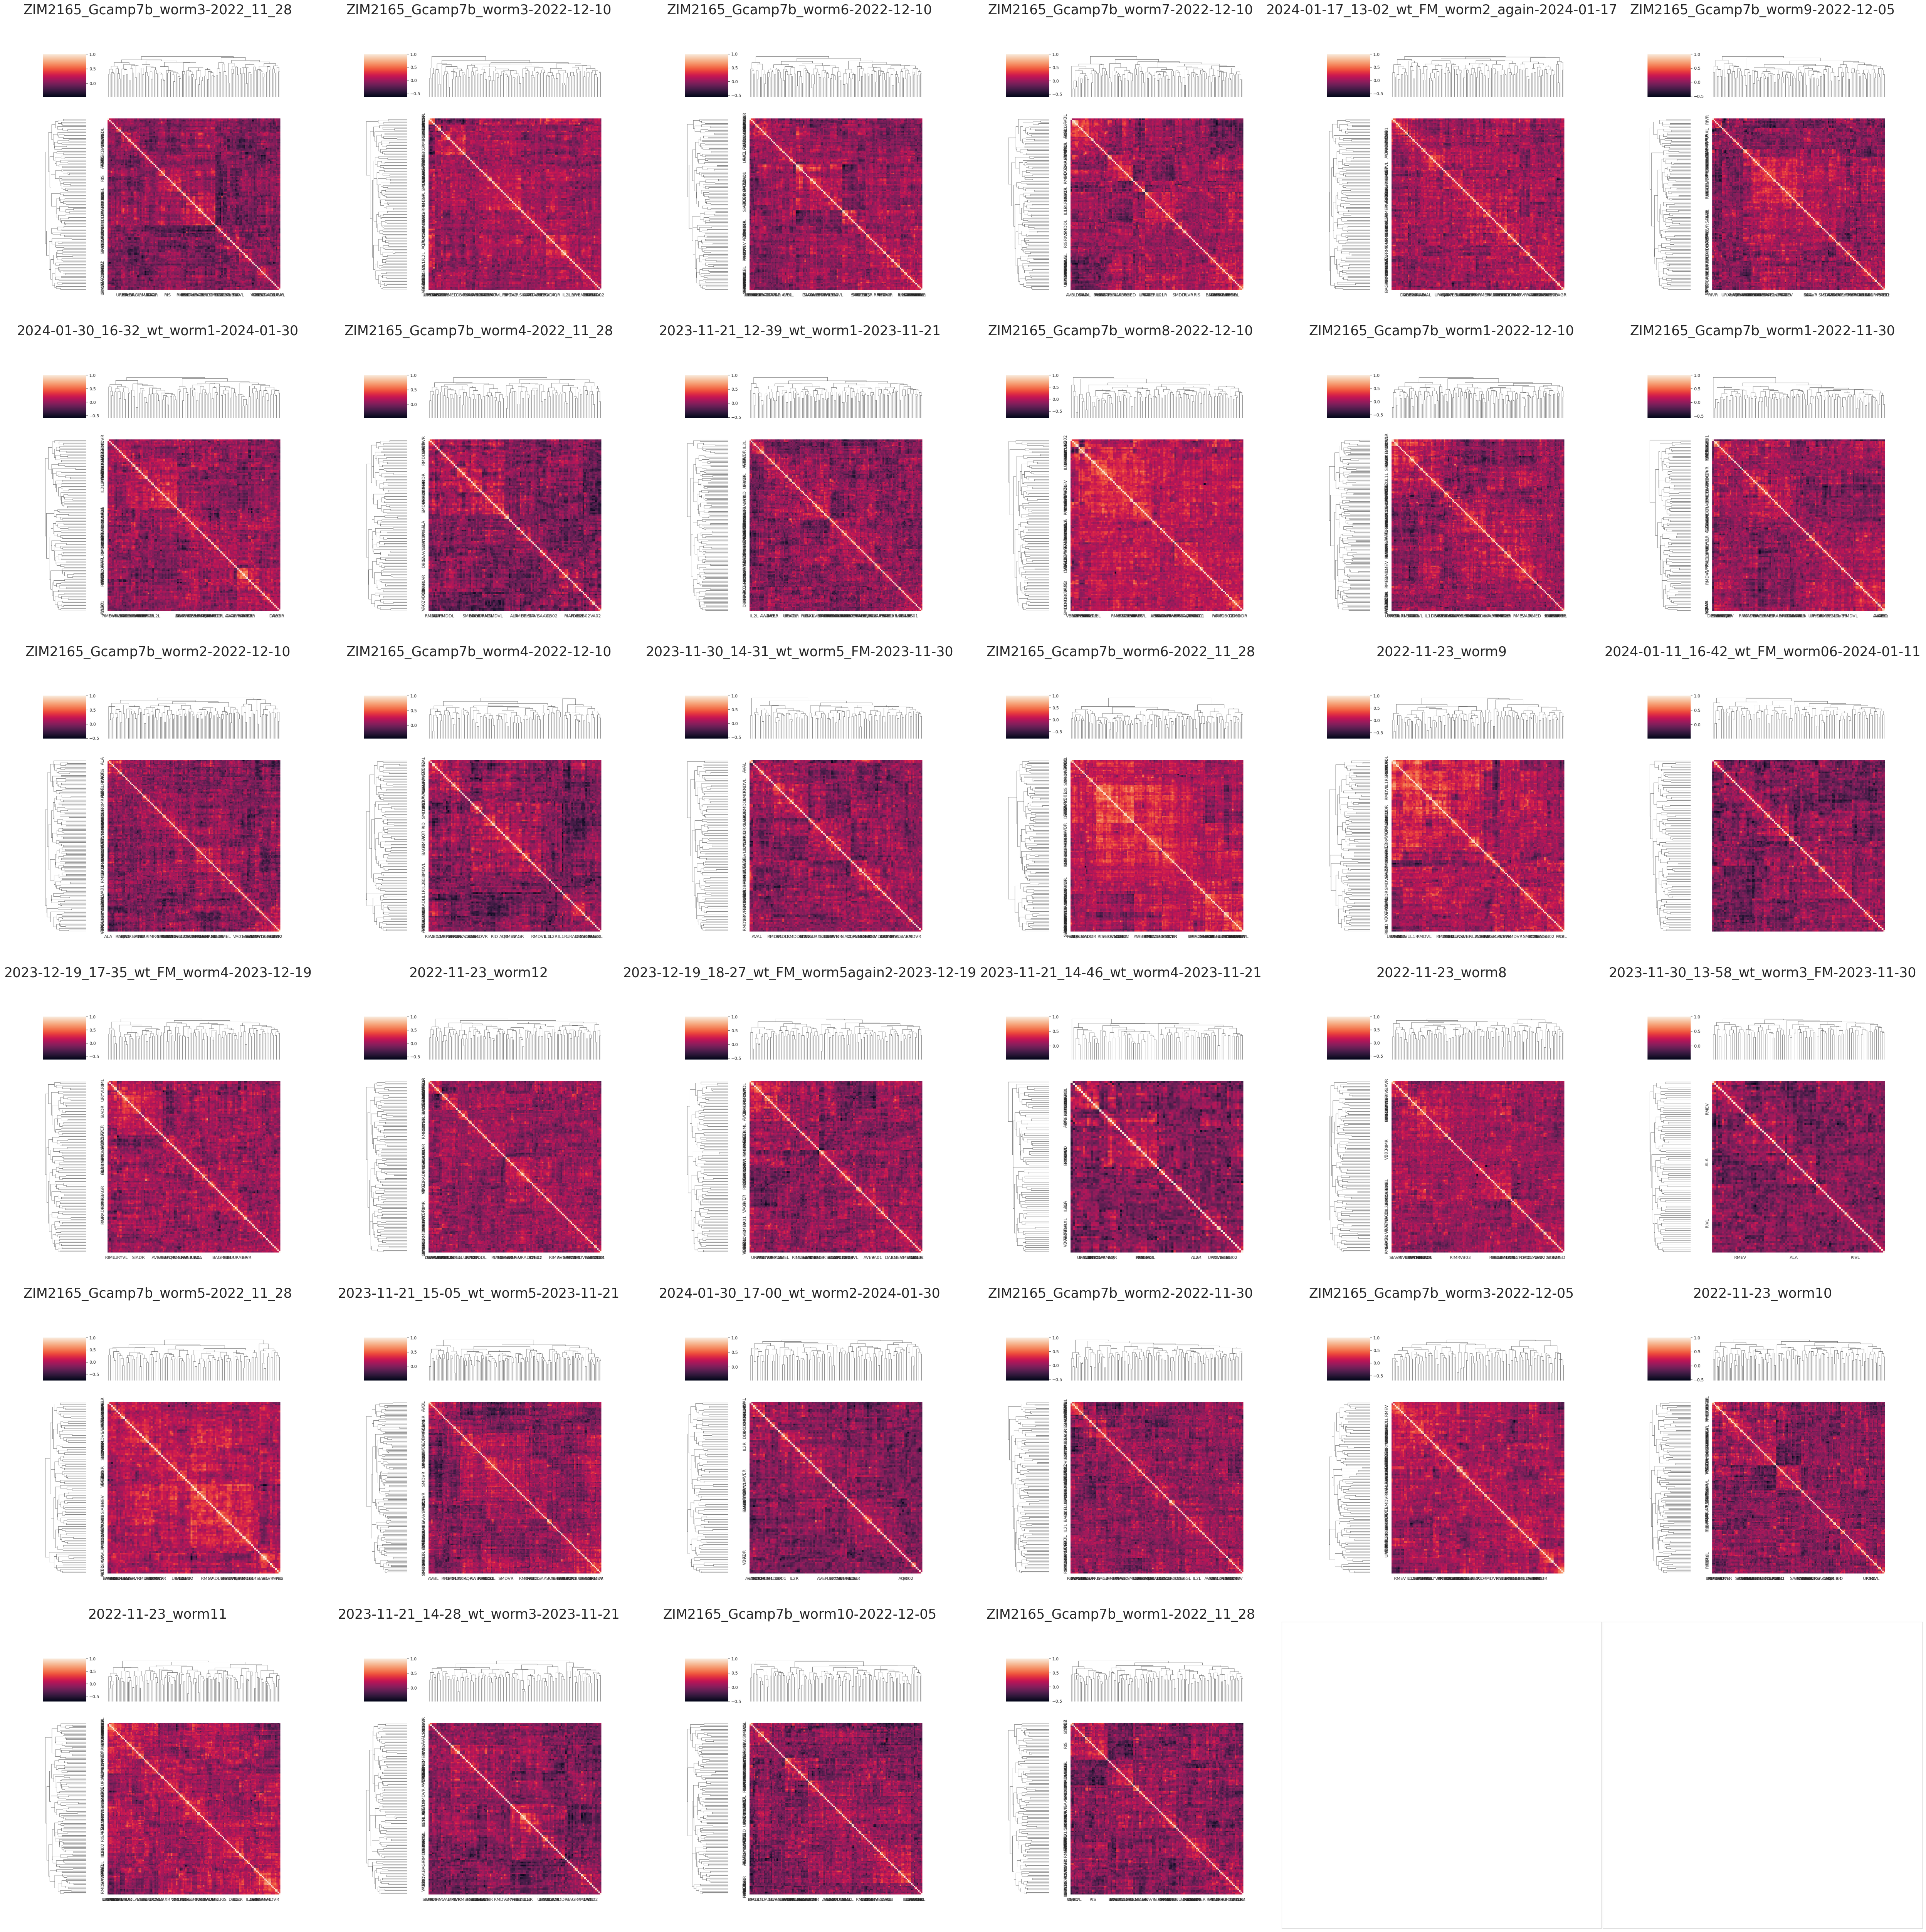

In [30]:
n = 4

traces_residual = list()
for i in range(len(filenames)):
	trace = traces[i]
	pca = PCA(n_components=n)
	trace_reduced = pca.fit_transform(trace)
	trace_reconstructed = pca.inverse_transform(trace_reduced)
	trace_residuals = trace - trace_reconstructed
	traces_residual.append(trace_residuals)

os.makedirs(f'{outpath}/residuals/pc{n}', exist_ok=True)

n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(50, 50))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, trace in enumerate(traces_residual):
	correlation = trace.corr()
	heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
	heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
	heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)

	image = np.frombuffer(heatmap.figure.canvas.tostring_argb(), dtype='uint8')
	image = image.reshape(heatmap.figure.canvas.get_width_height()[::-1] + (4,))
	image = image[:, :, [1, 2, 3]]

	axes[i // dim, i % dim].imshow(image)
	axes[i // dim, i % dim].axis('off')
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}', fontsize=25)

	plt.savefig(f'{outpath}/residuals/pc{n}/{filenames[i][:-14]}.png', dpi=300)
	plt.close(heatmap.figure)

plt.tight_layout(pad=0.2, w_pad=0.2, h_pad=0.2)
plt.show()


# behavior correlates

In [ ]:
continuous_behaviors = [get_continuous_behaviors(file) for file in hdf5files]

In [ ]:
n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(50, 50))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, behavior in enumerate(continuous_behaviors):
	if behavior is not None:
		correlation = behavior.corr()
		heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
		heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
		heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)

		image = np.frombuffer(heatmap.figure.canvas.tostring_argb(), dtype='uint8')
		image = image.reshape(heatmap.figure.canvas.get_width_height()[::-1] + (4,))
		image = image[:, :, [1, 2, 3]]

		axes[i // dim, i % dim].imshow(image)
		axes[i // dim, i % dim].axis('off')
		axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}', fontsize=16)

		plt.close(heatmap.figure)

plt.tight_layout(pad=0.2, w_pad=0.2, h_pad=0.2)
plt.show()

In [ ]:
continuous_behavior = get_continuous_behaviors(hdf5files[worm_id])

In [ ]:
correlation = continuous_behavior.corr()
heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=10)
heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=10)
heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)

plt.title(f'{filenames[worm_id][:-14]}', fontsize=12)
pass